In [ ]:
import tensorflow as tf
import os
# Hide INFO and WARNING messages
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [ ]:
import tensorflow as tf
# minst contain 70,000 comprezed in npz (numpy archive format) file 
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

# mnist.load_data() returns two tuples:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# we split training set into train and val
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)


In [6]:
print(f'Train samples {X_train.shape[0]}')
print(f'validation samples {X_val.shape[0]}')
print(f'Test samples {X_test.shape[0]}')
print(X_train.shape)

Train samples 48000
validation samples 12000
Test samples 10000
(48000, 28, 28)


X_train shape: (48000, 28, 28)| sample batch :
 [[  0  77 254 154   0]
 [  0 145 253  96   0]
 [  0 254 238  37   0]
 [  0 254 229   0   0]
 [  0 254 246  69   0]] 

A closeup of a sample patch (5x5 pixels):


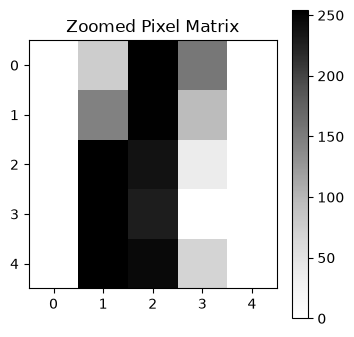

And the whole sample image:


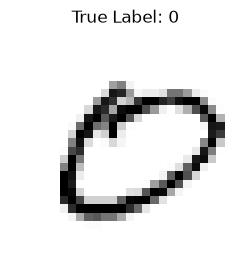

In [12]:
import matplotlib.pyplot as plt

print(f"X_train shape: {X_train.shape}| sample batch :\n {X_train[1, 15:20, 5:10]} ")


# 2. Visualize a zoomed-in patch
print("\nA closeup of a sample patch (5x5 pixels):")
plt.figure(figsize=(4, 4))

# imshow(): Displays an array as an image.
# interpolation="nearest": Displays each pixel as a distinct block
plt.imshow(X_train[1, 15:20, 5:10], cmap="Greys", interpolation="nearest")
plt.colorbar()  # Adds a scale bar showing float values between 0.0 and 1.0
plt.title("Zoomed Pixel Matrix")
plt.axis("on")  # Keeps axis ticks visible to show pixel coordinates
plt.show()


# 3. Visualize the full sample
print("And the whole sample image:")
plt.figure(figsize=(3, 3))
plt.imshow(X_train[1], cmap="Greys")
plt.title(f"True Label: {y_train[1]}")
plt.axis("off")  # Hides axis ticks for a clean image view
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
# Input defines the shape of the data that enters your neural network.
# Sequential is used to build a neural network by stacking layers one after another in a linear sequence.
# Dense creates a fully connected neural network layer

# 1. Preprocess Existing Data (Train, Val, Test)


# Normalize pixel values to [0.0, 1.0] for all splits
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Flatten images from 2D (28x28) to 1D vectors (784 features)
X_train = X_train.reshape(-1, 784)
X_val = X_val.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

# One-hot encode target labels for all splits
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=10)
y_val_oh = tf.keras.utils.to_categorical(y_val, num_classes=10)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=10)


# 2. Build Modern Neural Network Architecture

model = Sequential([
    Input(shape=(784,), name="input_layer"),
    Dense(128, activation='relu', name="hidden_dense_128"),
    Dense(10, activation='softmax', name="output_layer_10")
], name="mnist_mlp_model")

# 3. Compile the Model
# how your neural network will learn and how its performance will be measured during training.
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# 4. Display Model Summary

model.summary()


Model: "mnist_mlp_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_dense_128 (Dense)        │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer_10 (Dense)         │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# optimizer = tf.keras.optimizers.Adam(alpha = 0.01)

In [13]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [14]:
model.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=10,
    batch_size=64,
    verbose=1
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9069 - loss: 0.3322 - val_accuracy: 0.9498 - val_loss: 0.1822
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9571 - loss: 0.1488 - val_accuracy: 0.9608 - val_loss: 0.1328
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9698 - loss: 0.1044 - val_accuracy: 0.9690 - val_loss: 0.1080
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9769 - loss: 0.0783 - val_accuracy: 0.9700 - val_loss: 0.1011
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9822 - loss: 0.0612 - val_accuracy: 0.9728 - val_loss: 0.0870
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9862 - loss: 0.0484 - val_accuracy: 0.9722 - val_loss: 0.0908
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9882 - loss: 0.0402 - val_accuracy: 0.9739 - val_loss: 0.0900
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9910 - loss: 0.0326 - val_accuracy: 0